# Notebook 01: LOB Mechanics

**Paper Reference:** Gould et al. (2013), Section 2 — *A Mathematical Description of an LOB*

This notebook builds a limit order book from scratch, illustrating the core definitions:
- Orders as tuples $(p_x, \omega_x, t_x)$
- Tick size $\pi$ and lot size $\sigma$
- Bid price $b(t)$, ask price $a(t)$, spread $s(t)$, mid-price $m(t)$
- Depth profiles and relative pricing
- Matching and returns

In [1]:
import sys
sys.path.insert(0, '..')

from lob.order import limit_order, market_order, cancel_order, Side, OrderType, reset_order_id_counter
from lob.book import OrderBook
from lob.matching import PriceTimeEngine
from lob.metrics import compute_returns, compute_log_returns
from lob.analysis.plotting import set_style, plot_book_snapshot, plot_depth_profile, plot_price_series
import numpy as np
import matplotlib.pyplot as plt

set_style()
reset_order_id_counter()

## 1. Orders: The Building Blocks

From the paper: *"An order $x = (p_x, \omega_x, t_x)$ submitted at time $t_x$ with price $p_x$ and size $\omega_x > 0$ (respectively, $\omega_x < 0$) is a commitment to sell (respectively, buy) up to $|\omega_x|$ units of the traded asset at a price no less than (respectively, no greater than) $p_x$."*

In our implementation, we use explicit `Side.BID` / `Side.ASK` instead of sign conventions.

In [2]:
# A buy limit order: willing to buy 5 lots at price 100
bid = limit_order(price=100, size=5, timestamp=1.0, side=Side.BID)
print(f"Buy order:  price={bid.price}, size={bid.size}, time={bid.timestamp}, side={bid.side.value}")

# A sell limit order: willing to sell 3 lots at price 105
ask = limit_order(price=105, size=3, timestamp=2.0, side=Side.ASK)
print(f"Sell order: price={ask.price}, size={ask.size}, time={ask.timestamp}, side={ask.side.value}")

# A market order: buy immediately at whatever price is available
mo = market_order(size=2, timestamp=3.0, side=Side.BID)
print(f"Market buy: size={mo.size}, type={mo.order_type.value}")

Buy order:  price=100, size=5, time=1.0, side=bid
Sell order: price=105, size=3, time=2.0, side=ask
Market buy: size=2, type=market


## 2. Resolution Parameters

The paper defines:
- **Tick size** $\pi$: smallest permissible price interval
- **Lot size** $\sigma$: smallest tradeable quantity

These are the *resolution parameters* of an LOB. All orders must conform to them.

In [3]:
# Create a book with tick_size=5 and lot_size=10
strict_book = OrderBook(tick_size=5, lot_size=10)

# Valid order: price is multiple of 5, size is multiple of 10
strict_book.add_order(limit_order(100, 10, 1.0, Side.BID))
print(f"Valid order added. Best bid = {strict_book.best_bid}")

# Invalid price: 101 is not a multiple of 5
try:
    strict_book.add_order(limit_order(101, 10, 2.0, Side.BID))
except ValueError as e:
    print(f"Rejected! {e}")

# Invalid size: 3 is not a multiple of 10
try:
    strict_book.add_order(limit_order(100, 3, 3.0, Side.BID))
except ValueError as e:
    print(f"Rejected! {e}")

Valid order added. Best bid = 100
Rejected! Price 101 not a multiple of tick size 5
Rejected! Size 3 not a multiple of lot size 10


## 3. Building the Book

An LOB $L(t)$ is the set of all active orders at time $t$. Let's build one step by step.

In [4]:
book = OrderBook(tick_size=1, lot_size=1)
engine = PriceTimeEngine()

# Add bid-side orders (buyers)
bids = [
    limit_order(150, 8, 1.0, Side.BID),
    limit_order(150, 5, 1.1, Side.BID),   # same price, later time
    limit_order(149, 10, 1.2, Side.BID),
    limit_order(148, 3, 1.3, Side.BID),
    limit_order(147, 7, 1.4, Side.BID),
]

# Add ask-side orders (sellers)
asks = [
    limit_order(153, 6, 1.5, Side.ASK),
    limit_order(153, 4, 1.6, Side.ASK),   # same price, later time
    limit_order(154, 8, 1.7, Side.ASK),
    limit_order(155, 5, 1.8, Side.ASK),
    limit_order(156, 12, 1.9, Side.ASK),
]

for o in bids + asks:
    book.add_order(o)

print(book)
print(f"\nBid-side depth profile: {book.depth_profile(Side.BID, 5)}")
print(f"Ask-side depth profile: {book.depth_profile(Side.ASK, 5)}")

OrderBook(best_bid=150, best_ask=153, spread=3, bid_orders=5, ask_orders=5)

Bid-side depth profile: [(150, 13), (149, 10), (148, 3), (147, 7)]
Ask-side depth profile: [(153, 10), (154, 8), (155, 5), (156, 12)]


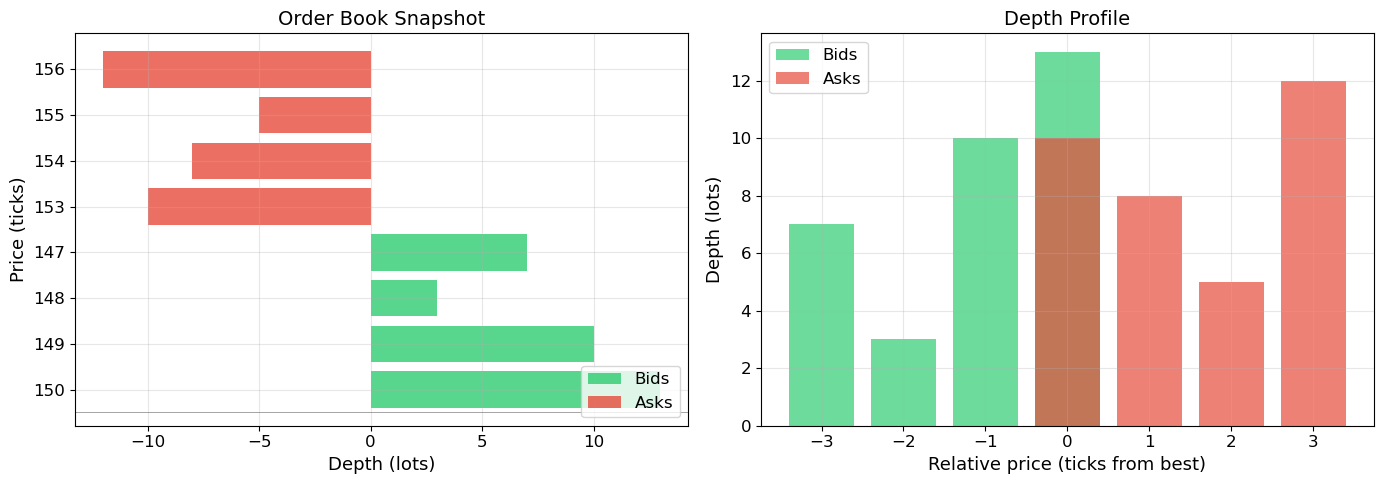

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_book_snapshot(book, n_levels=5, ax=axes[0], title="Order Book Snapshot")
plot_depth_profile(book, n_levels=5, ax=axes[1])
plt.tight_layout()
plt.show()

## 4. Bid, Ask, Spread, and Mid-Price

From the paper:
- $b(t) = \max_{x \in B(t)} p_x$ — **bid price** (highest buy order)
- $a(t) = \min_{x \in A(t)} p_x$ — **ask price** (lowest sell order)
- $s(t) = a(t) - b(t)$ — **bid-ask spread**
- $m(t) = [a(t) + b(t)] / 2$ — **mid-price**

In [6]:
print(f"b(t) = best bid  = {book.best_bid}")
print(f"a(t) = best ask  = {book.best_ask}")
print(f"s(t) = spread    = {book.spread} ticks")
print(f"m(t) = mid-price = {book.mid_price}")
print()
print(f"The spread of {book.spread} ticks means you 'pay' {book.spread} ticks")
print(f"for the immediacy of a market order vs. a limit order at the best price.")

b(t) = best bid  = 150
a(t) = best ask  = 153
s(t) = spread    = 3 ticks
m(t) = mid-price = 151.5

The spread of 3 ticks means you 'pay' 3 ticks
for the immediacy of a market order vs. a limit order at the best price.


## 5. Matching: Market Orders

When a buy market order arrives, it matches against the lowest-priced sell orders (best ask). The fill always occurs at the **maker's** price.

From the paper (Section 2.3): *"Whenever such a matching occurs, it does so at the price of the active order, which is not necessarily equal to the price of the incoming order."*

In [7]:
print("=== Before market order ===")
print(f"Best ask = {book.best_ask}, depth at best ask = {book.depth_at_price(153, Side.ASK)}")
print()

# Buy 5 lots at market
mo = market_order(size=5, timestamp=2.0, side=Side.BID)
fills = engine.process(book, mo)

print(f"Market buy for 5 lots:")
for f in fills:
    print(f"  Filled {f.size} lots at price {f.price} (maker order #{f.maker_order_id})")
print()
print(f"=== After market order ===")
print(f"Best ask = {book.best_ask}, depth at 153 = {book.depth_at_price(153, Side.ASK)}")
print(f"Spread = {book.spread}")

=== Before market order ===
Best ask = 153, depth at best ask = 10

Market buy for 5 lots:
  Filled 5 lots at price 153 (maker order #12)

=== After market order ===
Best ask = 153, depth at 153 = 5
Spread = 3


In [8]:
# A larger market order that sweeps multiple price levels
print("=== Sweeping market sell order ===")
print(f"Before: best bid = {book.best_bid}, depth at 150 = {book.depth_at_price(150, Side.BID)}")
print()

mo_sell = market_order(size=20, timestamp=3.0, side=Side.ASK)
fills = engine.process(book, mo_sell)

print(f"Market sell for 20 lots:")
total_filled = 0
for f in fills:
    print(f"  Filled {f.size} lots at price {f.price}")
    total_filled += f.size
print(f"Total filled: {total_filled} lots")
print()
print(f"After: best bid = {book.best_bid}, spread = {book.spread}")
print(f"Notice how the market order 'walked the book' through multiple price levels.")

=== Sweeping market sell order ===
Before: best bid = 150, depth at 150 = 13

Market sell for 20 lots:
  Filled 8 lots at price 150
  Filled 5 lots at price 150
  Filled 7 lots at price 149
Total filled: 20 lots

After: best bid = 149, spread = 4
Notice how the market order 'walked the book' through multiple price levels.


## 6. Depth Profiles and Relative Pricing

The paper defines **relative price**:
- For buy orders: $\delta^b(p) = b(t) - p$ (how far below the best bid)
- For sell orders: $\delta^a(p) = p - a(t)$ (how far above the best ask)

Most traders assess the LOB via relative depth profiles, and several studies show that order arrival rates depend on relative prices rather than actual prices.

In [9]:
# Rebuild a fresh book for cleaner visualization
book2 = OrderBook()
rng = np.random.default_rng(42)

# Create a realistic-looking book with varying depth
mid = 1000
for i in range(1, 16):
    # Bid side: depth peaks a few ticks from best, then declines
    depth = max(1, int(10 * np.exp(-0.1 * (i - 3)**2) + rng.integers(0, 3)))
    for _ in range(depth):
        book2.add_order(limit_order(mid - i, 1, float(i), Side.BID))
    # Ask side: similar pattern
    depth = max(1, int(10 * np.exp(-0.1 * (i - 3)**2) + rng.integers(0, 3)))
    for _ in range(depth):
        book2.add_order(limit_order(mid + i, 1, float(i), Side.ASK))

print("Absolute depth profile (bids):")
for price, depth in book2.depth_profile(Side.BID, 8):
    print(f"  Price {price}: {depth} lots")

print("\nRelative depth profile (bids):")
for delta, depth in book2.relative_depth_profile(Side.BID, 8):
    print(f"  delta={delta} ticks from best: {depth} lots")

Absolute depth profile (bids):
  Price 999: 6 lots
  Price 998: 10 lots
  Price 997: 11 lots
  Price 996: 9 lots
  Price 995: 6 lots
  Price 994: 5 lots
  Price 993: 4 lots
  Price 992: 2 lots

Relative depth profile (bids):
  delta=0 ticks from best: 6 lots
  delta=1 ticks from best: 10 lots
  delta=2 ticks from best: 11 lots
  delta=3 ticks from best: 9 lots
  delta=4 ticks from best: 6 lots
  delta=5 ticks from best: 5 lots
  delta=6 ticks from best: 4 lots
  delta=7 ticks from best: 2 lots


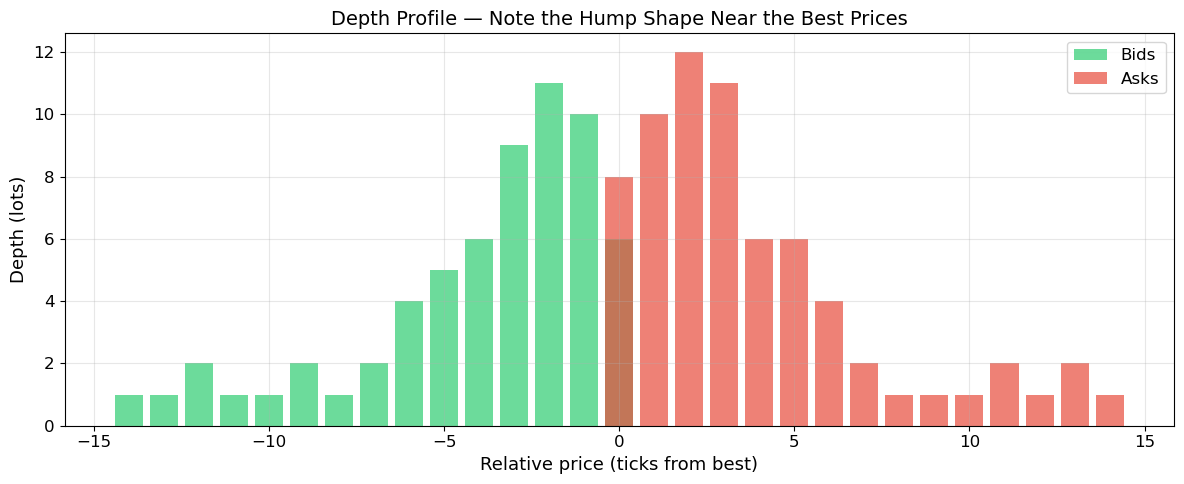

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
plot_depth_profile(book2, n_levels=15, ax=ax)
ax.set_title("Depth Profile — Note the Hump Shape Near the Best Prices")
plt.tight_layout()
plt.show()

## 7. Cancellations

Active orders can be cancelled at any time. From the paper: *"Cancellation usually occurs because the owner of an order no longer wishes to offer a trade at the stated price."*

In [11]:
book3 = OrderBook()
engine3 = PriceTimeEngine()

o1 = limit_order(100, 5, 1.0, Side.BID)
o2 = limit_order(100, 3, 2.0, Side.BID)
o3 = limit_order(99, 7, 3.0, Side.BID)
for o in [o1, o2, o3]:
    book3.add_order(o)

print(f"Before cancel: depth at 100 = {book3.depth_at_price(100, Side.BID)}, total orders = {book3.num_orders()}")

# Cancel order o1
removed = book3.cancel_order(o1.order_id)
print(f"Cancelled order #{removed.order_id} (size={removed.size} at price {removed.price})")
print(f"After cancel:  depth at 100 = {book3.depth_at_price(100, Side.BID)}, total orders = {book3.num_orders()}")

Before cancel: depth at 100 = 8, total orders = 3
Cancelled order #149 (size=5 at price 100)
After cancel:  depth at 100 = 3, total orders = 2


## 8. Returns

The paper defines:
- **Return**: $R^m(t_1, t_2) = (m(t_2) - m(t_1)) / m(t_1)$
- **Log return**: $r^m(t_1, t_2) = \log(m(t_2) / m(t_1))$

Let's generate a short price series by submitting market orders and tracking the mid-price.

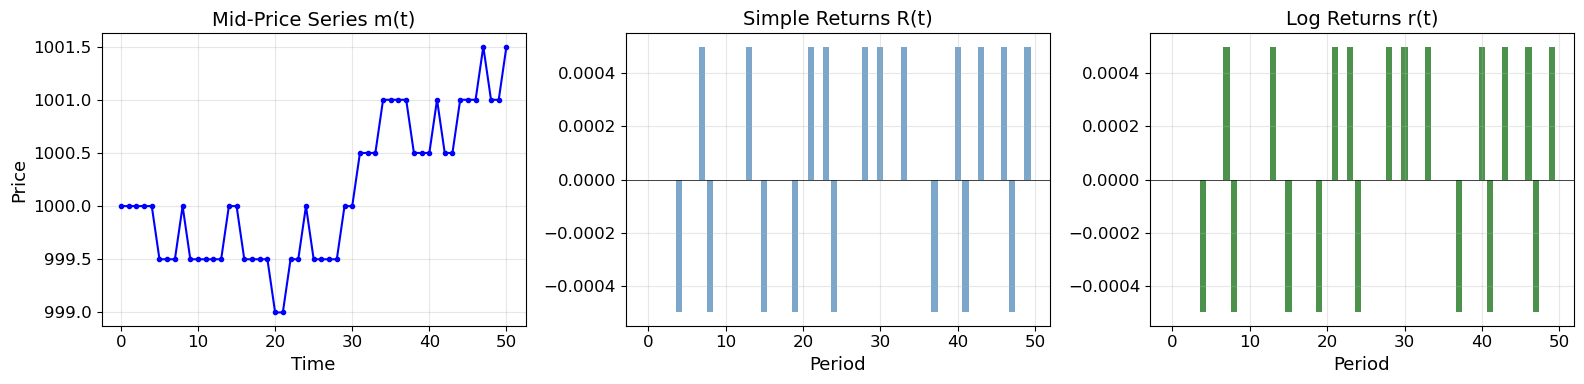

Mean return: 0.000030
Std of returns: 0.000307
Note: returns and log returns are nearly identical for small price changes.


In [12]:
# Build a fresh book and submit market orders to generate price changes
book4 = OrderBook()
engine4 = PriceTimeEngine()
rng = np.random.default_rng(123)

# Seed the book with many limit orders
mid = 1000
for i in range(1, 30):
    for _ in range(5):
        book4.add_order(limit_order(mid - i, 1, 0.0, Side.BID))
        book4.add_order(limit_order(mid + i, 1, 0.0, Side.ASK))

# Submit random market orders and track mid-price
mid_prices = [book4.mid_price]
times = [0.0]

for i in range(1, 51):
    side = Side.BID if rng.random() < 0.5 else Side.ASK
    size = rng.integers(1, 4)
    mo = market_order(size=size, timestamp=float(i), side=side)
    engine4.process(book4, mo)
    if book4.mid_price is not None:
        mid_prices.append(book4.mid_price)
        times.append(float(i))

mid_prices = np.array(mid_prices)
times = np.array(times)

returns = compute_returns(mid_prices)
log_returns = compute_log_returns(mid_prices)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(times, mid_prices, 'b-o', markersize=3)
axes[0].set_title('Mid-Price Series m(t)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Price')

axes[1].bar(range(len(returns)), returns, color='steelblue', alpha=0.7)
axes[1].set_title('Simple Returns R(t)')
axes[1].set_xlabel('Period')
axes[1].axhline(y=0, color='black', linewidth=0.5)

axes[2].bar(range(len(log_returns)), log_returns, color='darkgreen', alpha=0.7)
axes[2].set_title('Log Returns r(t)')
axes[2].set_xlabel('Period')
axes[2].axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

print(f"Mean return: {returns.mean():.6f}")
print(f"Std of returns: {returns.std():.6f}")
print(f"Note: returns and log returns are nearly identical for small price changes.")

## Summary

We've built a limit order book from scratch and explored the key definitions from Section 2 of Gould et al. (2013):

| Concept | Paper Notation | Our Implementation |
|---------|---------------|--------------------|
| Order | $x = (p_x, \omega_x, t_x)$ | `limit_order(price, size, timestamp, side)` |
| Tick size | $\pi$ | `OrderBook(tick_size=...)` |
| Lot size | $\sigma$ | `OrderBook(lot_size=...)` |
| Bid price | $b(t)$ | `book.best_bid` |
| Ask price | $a(t)$ | `book.best_ask` |
| Spread | $s(t) = a(t) - b(t)$ | `book.spread` |
| Mid-price | $m(t) = [a(t) + b(t)]/2$ | `book.mid_price` |
| Depth | $n^b(p, t)$ | `book.depth_at_price(p, side)` |
| Relative price | $\delta^b = b(t) - p$ | `book.relative_depth_profile()` |

**Next:** Notebook 02 explores matching algorithms and priority rules (Section 3).